# SilverAI - Target Creation

This notebook creates leakage-safe regression and classification targets for the next three 5-minute COMEX silver futures candles (15 minutes). It does not train a model or change the existing 17 candidate features.

## 1. Objective

For each candle at time `t`, calculate the percentage return from `close[t]` to `close[t+3]`. Keep only rows where the current candle and the next three candles are consecutive 5-minute intervals. Create both a continuous regression target and a three-class direction target.

## 2. Imports and Configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = Path('..').resolve()

INPUT_PATH = PROJECT_ROOT / 'data' / 'silver_features.csv'
OUTPUT_PATH = PROJECT_ROOT / 'data' / 'silver_modeling_data.csv'
FIGURES_PATH = PROJECT_ROOT / 'reports' / 'figures'
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

HORIZON_BARS = 3
BAR_INTERVAL = pd.Timedelta(minutes=5)
HORIZON_INTERVAL = HORIZON_BARS * BAR_INTERVAL

# Provisional diagnostic value only; not selected from validation or test data.
# Calibrate a final threshold from training data only before model training.
NEUTRAL_THRESHOLD_PCT = 0.05
ILLUSTRATIVE_THRESHOLDS_PCT = [0.00, 0.01, 0.02, 0.05, 0.10]

print(f'Input: {INPUT_PATH}')
print(f'Output: {OUTPUT_PATH}')
print(f'Diagnostic neutral threshold: +/-{NEUTRAL_THRESHOLD_PCT:.2f}% (PROVISIONAL)')

Input: C:\Users\ravik\Desktop\SilverAI\data\silver_features.csv
Output: C:\Users\ravik\Desktop\SilverAI\data\silver_modeling_data.csv
Diagnostic neutral threshold: +/-0.05% (PROVISIONAL)


## 3. Load Feature Dataset

In [2]:
df = pd.read_csv(INPUT_PATH)
input_row_count = len(df)
required_columns = {'datetime_et', 'close'}
missing_required = required_columns.difference(df.columns)
if missing_required:
    raise ValueError(f'Missing required columns: {sorted(missing_required)}')

feature_columns = [
    'return_1', 'return_3', 'return_6',
    'volatility_5', 'volatility_20', 'volatility_50',
    'sma_distance_20', 'sma_distance_50',
    'candle_return', 'candle_range_pct', 'upper_wick_ratio', 'lower_wick_ratio',
    'relative_volume', 'volume_change',
    'hour_sin', 'hour_cos', 'day_of_week',
]
if not set(feature_columns).issubset(df.columns):
    raise ValueError('The input dataset does not contain the expected 17 candidate features.')

print(f'Input rows: {input_row_count:,}')
print(f'Input columns: {df.shape[1]}')
df.head(2)

Input rows: 189,798
Input columns: 23


,datetime_et,open,high,low,close,volume,return_1,return_3,return_6,volatility_5,volatility_20,volatility_50,sma_distance_20,sma_distance_50,candle_return,candle_range_pct,upper_wick_ratio,lower_wick_ratio,relative_volume,volume_change,hour_sin,hour_cos,day_of_week
0,2023-11-01 02:10:00-04:00,22.75,22.79,22.745,22.770,229,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.087912,0.197628,0.444444,0.111111,0.0,0.000000,0.53730,0.843391,2
1,2023-11-01 02:15:00-04:00,22.77,22.79,22.765,22.785,84,0.065876,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.065876,0.109721,0.200000,0.200000,0.0,-63.318777,0.55557,0.831470,2


## 4. Validate Data and Timestamps

The original `datetime_et` strings are preserved. A separate UTC-normalized timestamp is used only for unambiguous elapsed-time arithmetic across daylight-saving offset changes; this is explicit and does not alter the saved timestamp column. A valid horizon requires exact timestamps at +5, +10, and +15 minutes.

In [3]:
df['_timestamp_for_validation'] = pd.to_datetime(df['datetime_et'], errors='coerce', utc=True)
if df['_timestamp_for_validation'].isna().any():
    raise ValueError('Unparseable datetime_et values found.')

timestamp_ordered = df['_timestamp_for_validation'].is_monotonic_increasing
duplicate_timestamp_count = int(df['_timestamp_for_validation'].duplicated(keep=False).sum())
timestamp_diffs = df['_timestamp_for_validation'].diff().dropna()
gap_count = int((timestamp_diffs != BAR_INTERVAL).sum())

if not timestamp_ordered:
    raise ValueError('datetime_et is not in chronological order; refusing to reorder silently.')

print(f'Timestamp order is chronological: {timestamp_ordered}')
print(f'Duplicate timestamp rows: {duplicate_timestamp_count:,}')
print(f'Non-5-minute adjacent intervals: {gap_count:,}')
print(f'Timestamp range: {df["datetime_et"].iloc[0]} to {df["datetime_et"].iloc[-1]}')

Timestamp order is chronological: True
Duplicate timestamp rows: 0
Non-5-minute adjacent intervals: 13,031
Timestamp range: 2023-11-01 02:10:00-04:00 to 2026-11-03 02:00:00-05:00


## 5. Create 15-Minute Future Price

In [4]:
future_timestamp_15m = df['_timestamp_for_validation'].shift(-HORIZON_BARS)
future_close_15m = df['close'].shift(-HORIZON_BARS)

expected_t1 = df['_timestamp_for_validation'].shift(-1) == df['_timestamp_for_validation'] + BAR_INTERVAL
expected_t2 = df['_timestamp_for_validation'].shift(-2) == df['_timestamp_for_validation'] + (2 * BAR_INTERVAL)
expected_t3 = df['_timestamp_for_validation'].shift(-3) == df['_timestamp_for_validation'] + (3 * BAR_INTERVAL)
valid_horizon = expected_t1 & expected_t2 & expected_t3 & future_close_15m.notna()

# The final three rows cannot have a complete future horizon. Rows near any gap also fail explicitly.
invalid_horizon_count = int((~valid_horizon).sum())
final_three_invalid = int((~valid_horizon.tail(HORIZON_BARS)).sum())

print(f'Valid 15-minute horizons: {int(valid_horizon.sum()):,}')
print(f'Rows excluded for invalid horizon: {invalid_horizon_count:,}')
print(f'Final three rows excluded for missing future observations: {final_three_invalid:,}')
print(f'All valid future timestamp differences are 15 minutes: {bool((future_timestamp_15m[valid_horizon] - df.loc[valid_horizon, "_timestamp_for_validation"] == HORIZON_INTERVAL).all())}')

Valid 15-minute horizons: 160,612
Rows excluded for invalid horizon: 29,186
Final three rows excluded for missing future observations: 3
All valid future timestamp differences are 15 minutes: True


## 6. Calculate Future Return

In [5]:
if (df['close'] <= 0).any():
    raise ValueError('Non-positive close values prevent a safe percentage-return calculation.')

future_return_15m = ((future_close_15m - df['close']) / df['close']) * 100.0
future_return_15m = future_return_15m.where(valid_horizon)

return_summary = future_return_15m[valid_horizon].describe(percentiles=[.01, .05, .25, .50, .75, .95, .99])
display(return_summary.to_frame('future_return_15m_pct'))
print(f'Mean: {future_return_15m[valid_horizon].mean():.6f}%')
print(f'Median: {future_return_15m[valid_horizon].median():.6f}%')
print(f'Standard deviation: {future_return_15m[valid_horizon].std():.6f}%')
print(f'Minimum: {future_return_15m[valid_horizon].min():.6f}%')
print(f'Maximum: {future_return_15m[valid_horizon].max():.6f}%')

,future_return_15m_pct
count,160612.000000
mean,0.001589
std,0.310927
min,-9.361259
1%,-0.895720
5%,-0.415866
25%,-0.113581
50%,0.000000
75%,0.123672
95%,0.412704


Mean: 0.001589%
Median: 0.000000%
Standard deviation: 0.310927%
Minimum: -9.361259%
Maximum: 11.432937%


## 7. Create Direction Labels

The diagnostic threshold is provisional and illustrative. It is not selected from validation or test data and must be calibrated from training data only before final model training.

In [6]:
def create_direction_labels(future_return_pct: pd.Series, neutral_threshold_pct: float) -> pd.Series:
    if neutral_threshold_pct < 0:
        raise ValueError('neutral_threshold_pct must be non-negative.')
    labels = pd.Series(np.nan, index=future_return_pct.index, dtype='float64')
    labels.loc[future_return_pct > neutral_threshold_pct] = 1
    labels.loc[future_return_pct < -neutral_threshold_pct] = -1
    labels.loc[future_return_pct.notna() & labels.isna()] = 0
    return labels.astype('Int64')

target_direction_15m = create_direction_labels(future_return_15m, NEUTRAL_THRESHOLD_PCT)
print(f'Applied provisional threshold: +/-{NEUTRAL_THRESHOLD_PCT:.2f}%')
display(target_direction_15m.value_counts(dropna=False).sort_index().rename('count').to_frame())

Applied provisional threshold: +/-0.05%


,count
-1,59335
0,38364
1,62913
<NA>,29186


## 8. Target Distribution Analysis

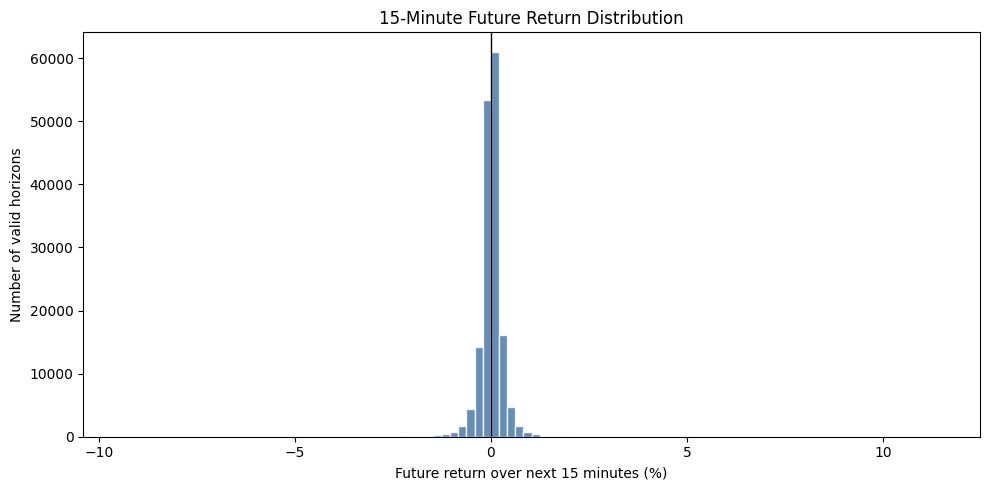

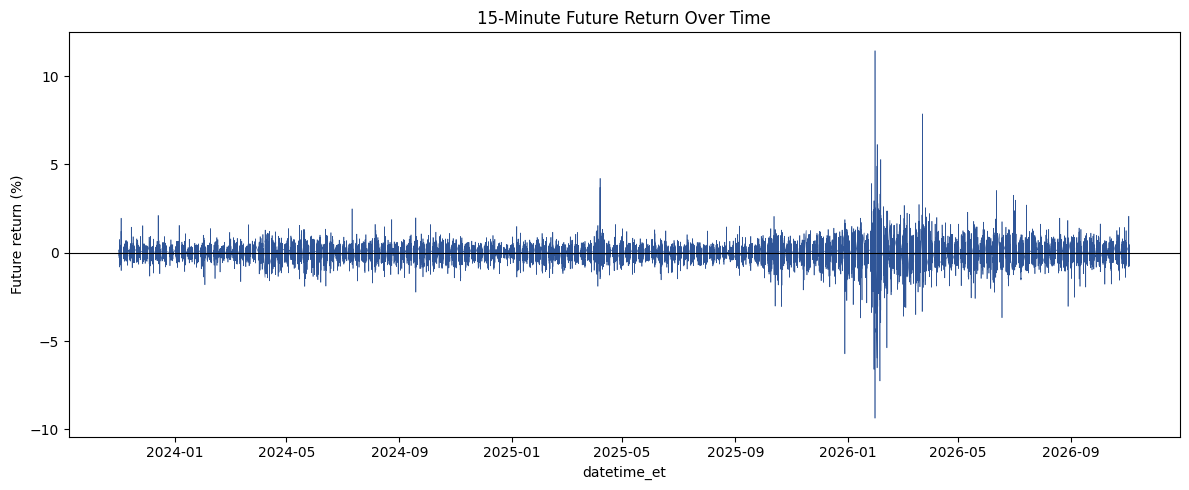

In [7]:
valid_returns = future_return_15m[valid_horizon].dropna()

plt.figure(figsize=(10, 5))
plt.hist(valid_returns, bins=100, color='#4C78A8', alpha=0.85, edgecolor='white')
plt.axvline(0, color='black', linewidth=1)
plt.title('15-Minute Future Return Distribution')
plt.xlabel('Future return over next 15 minutes (%)')
plt.ylabel('Number of valid horizons')
plt.tight_layout()
plt.savefig(FIGURES_PATH / '08_future_return_distribution.png', dpi=160)
plt.show()

valid_time = df.loc[valid_horizon, ['datetime_et']].copy()
valid_time['future_return_15m'] = valid_returns.to_numpy()
plt.figure(figsize=(12, 5))
plt.plot(pd.to_datetime(valid_time['datetime_et'], utc=True), valid_time['future_return_15m'], linewidth=0.45, color='#2F5597')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('15-Minute Future Return Over Time')
plt.xlabel('datetime_et')
plt.ylabel('Future return (%)')
plt.tight_layout()
plt.savefig(FIGURES_PATH / '09_future_return_over_time.png', dpi=160)
plt.show()

,DOWN (-1),NEUTRAL (0),UP (1)
±0.00%,75467,5635,79510
±0.01%,74860,6852,78900
±0.02%,70217,16093,74302
±0.05%,59335,38364,62913
±0.10%,44002,69899,46711


,DOWN (-1) (%),NEUTRAL (0) (%),UP (1) (%)
±0.00%,46.99,3.51,49.50
±0.01%,46.61,4.27,49.12
±0.02%,43.72,10.02,46.26
±0.05%,36.94,23.89,39.17
±0.10%,27.40,43.52,29.08


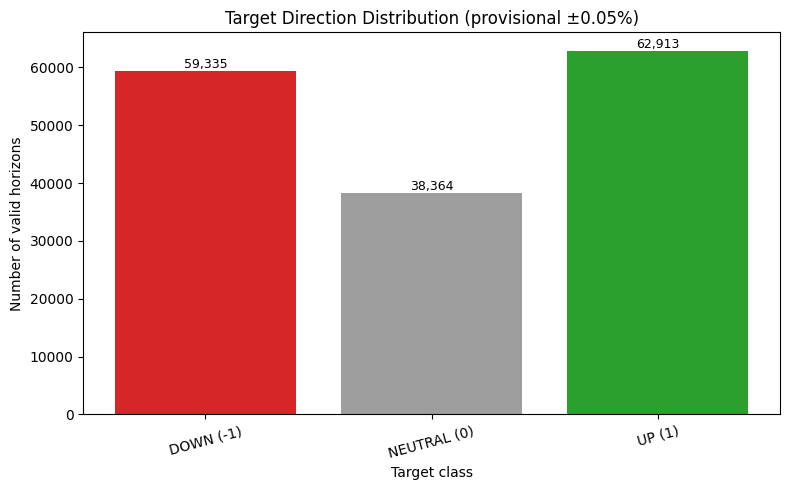

In [8]:
def class_distribution(return_series: pd.Series, threshold_pct: float) -> pd.Series:
    labels = create_direction_labels(return_series, threshold_pct).dropna().astype(int)
    counts = labels.value_counts().reindex([-1, 0, 1], fill_value=0)
    counts.index = ['DOWN (-1)', 'NEUTRAL (0)', 'UP (1)']
    return counts

threshold_table = pd.DataFrame({
    f'±{threshold:.2f}%': class_distribution(valid_returns, threshold)
    for threshold in ILLUSTRATIVE_THRESHOLDS_PCT
}).T
threshold_percentages = threshold_table.div(threshold_table.sum(axis=1), axis=0).mul(100).round(2)
display(threshold_table)
display(threshold_percentages.rename(columns=lambda c: f'{c} (%)'))

selected_counts = class_distribution(valid_returns, NEUTRAL_THRESHOLD_PCT)
plt.figure(figsize=(8, 5))
bars = plt.bar(selected_counts.index, selected_counts.values, color=['#D62728', '#9E9E9E', '#2CA02C'])
plt.title(f'Target Direction Distribution (provisional ±{NEUTRAL_THRESHOLD_PCT:.2f}%)')
plt.xlabel('Target class')
plt.ylabel('Number of valid horizons')
plt.xticks(rotation=15)
for bar, value in zip(bars, selected_counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value, f'{value:,}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_PATH / '10_target_class_distribution.png', dpi=160)
plt.show()

## 9. Leakage and Horizon Validation

The future close and future return are used only to construct targets. They are not included in the feature matrix. The output is kept chronological, and invalid horizons are excluded rather than forward-filled, interpolated, or replaced by the next available row.

In [9]:
target_columns = ['future_return_15m', 'target_direction_15m']
assert future_return_15m[~valid_horizon].isna().all()
assert target_direction_15m[~valid_horizon].isna().all()
assert set(target_columns).isdisjoint(feature_columns)
assert input_row_count == len(df)
assert valid_horizon.sum() == len(valid_returns)

# Optional chronological split illustration: any threshold calibration must use only this training segment.
train_cut = int(len(valid_returns) * 0.70)
training_returns_only = valid_returns.iloc[:train_cut]
print('Leakage checks passed:')
print(f'  Future target values are absent from invalid rows: {future_return_15m[~valid_horizon].isna().all()}')
print(f'  Target columns excluded from candidate features: {set(target_columns).isdisjoint(feature_columns)}')
print(f'  Chronological training illustration rows: {len(training_returns_only):,}')
print('  Final threshold remains provisional; no validation/test data was used to select it.')

Leakage checks passed:
  Future target values are absent from invalid rows: True
  Target columns excluded from candidate features: True
  Chronological training illustration rows: 112,428
  Final threshold remains provisional; no validation/test data was used to select it.


## 10. Save Modeling Dataset

In [10]:
modeling_data = df.loc[valid_horizon].drop(columns=['_timestamp_for_validation']).copy()
modeling_data['future_return_15m'] = future_return_15m.loc[valid_horizon].to_numpy()
modeling_data['target_direction_15m'] = target_direction_15m.loc[valid_horizon].to_numpy(dtype='int64')

expected_output_columns = [column for column in df.columns if column != '_timestamp_for_validation'] + target_columns
if modeling_data.columns.tolist() != expected_output_columns:
    raise AssertionError('Output column order does not preserve input columns followed by target columns.')

modeling_data.to_csv(OUTPUT_PATH, index=False)
reloaded = pd.read_csv(OUTPUT_PATH)
if len(reloaded) != len(modeling_data):
    raise AssertionError('Reloaded dataset row count differs from the saved dataset.')
if reloaded.columns.tolist() != modeling_data.columns.tolist():
    raise AssertionError('Reloaded dataset schema differs from the saved dataset.')

print(f'Saved and reloaded: {OUTPUT_PATH}')
print(f'Output shape: {reloaded.shape}')

Saved and reloaded: C:\Users\ravik\Desktop\SilverAI\data\silver_modeling_data.csv
Output shape: (160612, 25)


## 11. Final Summary

In [11]:
final_counts = reloaded['target_direction_15m'].value_counts().reindex([-1, 0, 1], fill_value=0)
final_percentages = (final_counts / len(reloaded) * 100).round(2)
summary = pd.Series({
    'Input row count': input_row_count,
    'Valid target row count': len(reloaded),
    'Rows removed due to invalid horizon': invalid_horizon_count,
    'Start timestamp': reloaded['datetime_et'].iloc[0],
    'End timestamp': reloaded['datetime_et'].iloc[-1],
    'Prediction horizon': '15 minutes / 3 consecutive 5-minute candles',
    'Target columns': ', '.join(target_columns),
    'Future return mean (%)': round(reloaded['future_return_15m'].mean(), 6),
    'Future return median (%)': round(reloaded['future_return_15m'].median(), 6),
    'Future return std. dev. (%)': round(reloaded['future_return_15m'].std(), 6),
    'Classification threshold': f'±{NEUTRAL_THRESHOLD_PCT:.2f}% (PROVISIONAL)',
    'DOWN count / percentage': f'{final_counts.loc[-1]:,} / {final_percentages.loc[-1]:.2f}%',
    'NEUTRAL count / percentage': f'{final_counts.loc[0]:,} / {final_percentages.loc[0]:.2f}%',
    'UP count / percentage': f'{final_counts.loc[1]:,} / {final_percentages.loc[1]:.2f}%',
    'Output file': str(OUTPUT_PATH),
})
display(summary.to_frame('value'))

,value
Input row count,189798
Valid target row count,160612
Rows removed due to invalid horizon,29186
Start timestamp,2023-11-01 02:10:00-04:00
End timestamp,2026-11-03 01:45:00-05:00
Prediction horizon,15 minutes / 3 consecutive 5-minute candles
Target columns,"future_return_15m, target_direction_15m"
Future return mean (%),0.001589
Future return median (%),0.0
Future return std. dev. (%),0.310927
